# Figure 2

In [4]:
%load_ext autoreload
%autoreload 2 
from pathlib import Path
import math
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from scipy.stats import ttest_rel
from scipy.optimize import brentq
from matplotlib.ticker import FixedLocator

from adaptive_behavior import data_access, plotting
from adaptive_behavior.data_access import AddExtraColumns as Add
from adaptive_behavior.helpers import repo_root
from adaptive_behavior.style import apply_style, panel_fig, save_panel, PALETTE

color1, color2, color3 = "#d95f02", "#1b9e77", "#7570b3"
color_dict_label = {"90": color1, "60": color2, "0": color3}

S3_ROOT = "s3://aind-scratch-data/vr-foraging/vr-foraging-manuscript"
STORAGE_OPTIONS = {"skip_signature": "true"}
STAGES_CSV = "C:/git/aind-vr-foraging-paper/code/notebooks/results/sessions_stages.csv"

apply_style()
PANELS_DIR = repo_root() / "figures" / "fig2" / "panels"
PANELS_DIR.mkdir(parents=True, exist_ok=True)
print("Panels will be saved to:", PANELS_DIR)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Panels will be saved to: C:\git\cosyne2026_adaptive_behavior\figures\fig2\panels


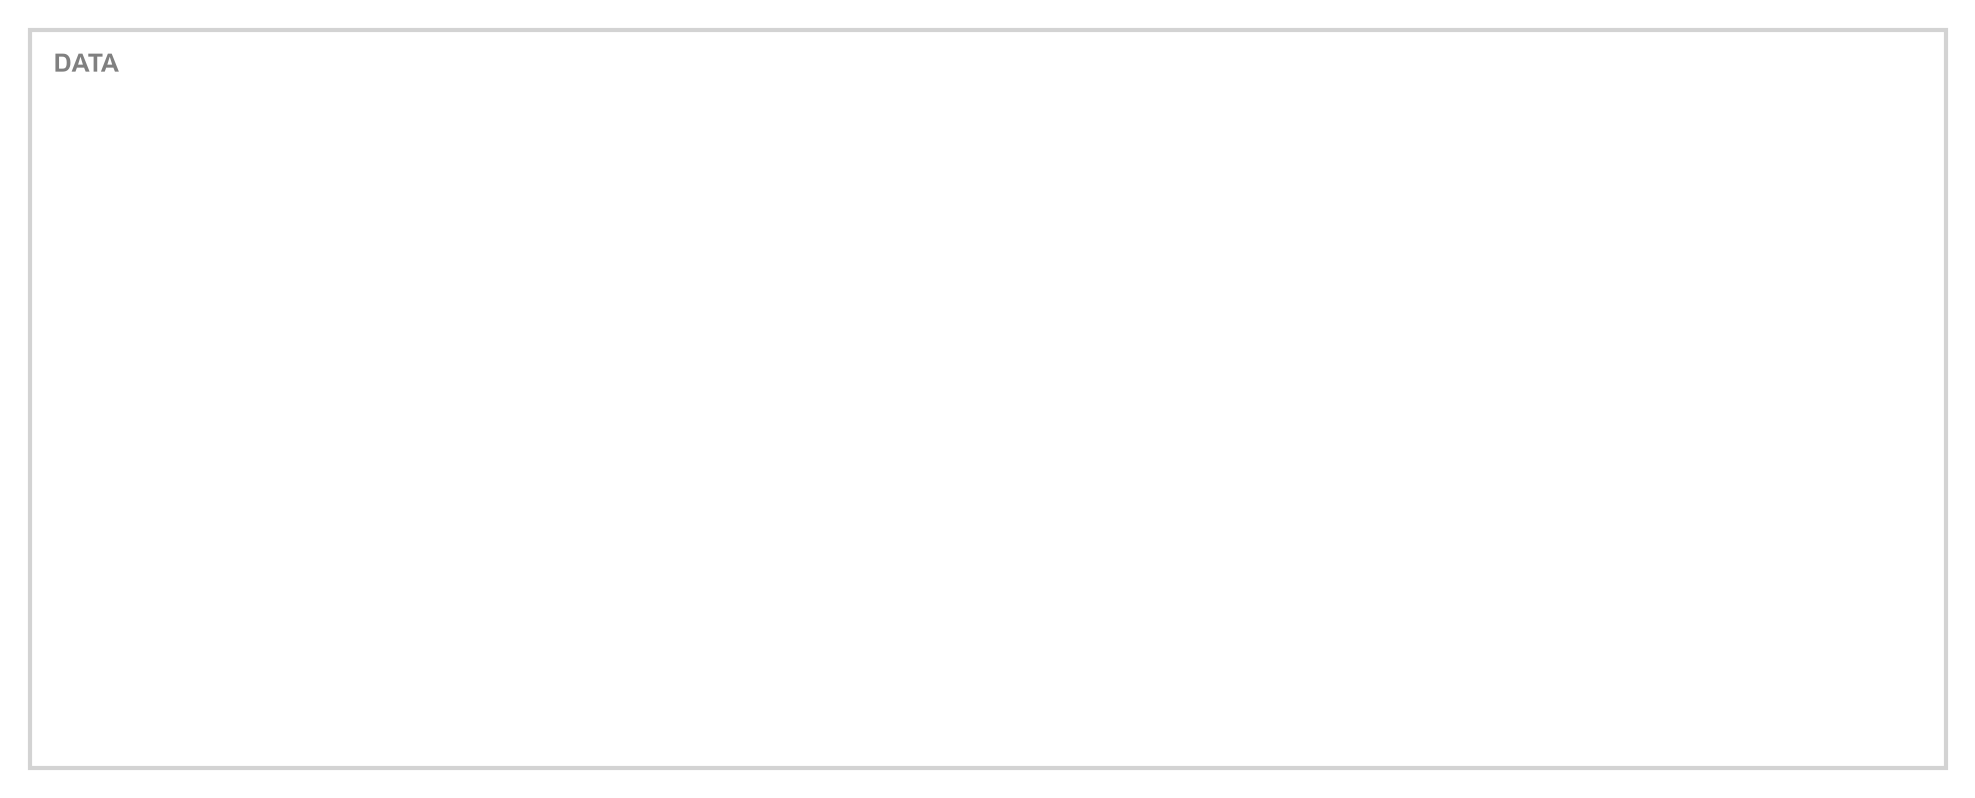

In [13]:
# Get the position of an existing axes
from matplotlib import patches



fig, ax = panel_fig("fig2_Z", nrows=1) # the subplot you want to frame
w_in, h_in = fig.get_size_inches()

inset = 0.4 / 25.4  # inches: keep the line inside the PDF page edge
x0, y0 = inset / w_in, inset / h_in  # frame covers the whole figure, not just the axes
width, height = 1 - 2 * x0, 1 - 2 * y0
pad_x, pad_y = 2 / 25.4 / w_in, 2 / 25.4 / h_in  # 2 mm text offset

# Then use these in FancyBboxPatch
rect = patches.FancyBboxPatch(
    (x0, y0), width, height,
    boxstyle="square,pad=0",
    linewidth=1,
    edgecolor='lightgrey',
    facecolor='none',
    transform=fig.transFigure,
    clip_on=False
)
fig.add_artist(rect)
ax.set_visible(False)
# label in the top-left corner of the frame
fig.text(x0 + pad_x, y0 + height - pad_y, "DATA", ha="left", va="top", fontsize=6, fontweight="bold", color="grey")
plt.show()
save_panel(fig, PANELS_DIR / "fig2_Z.pdf")

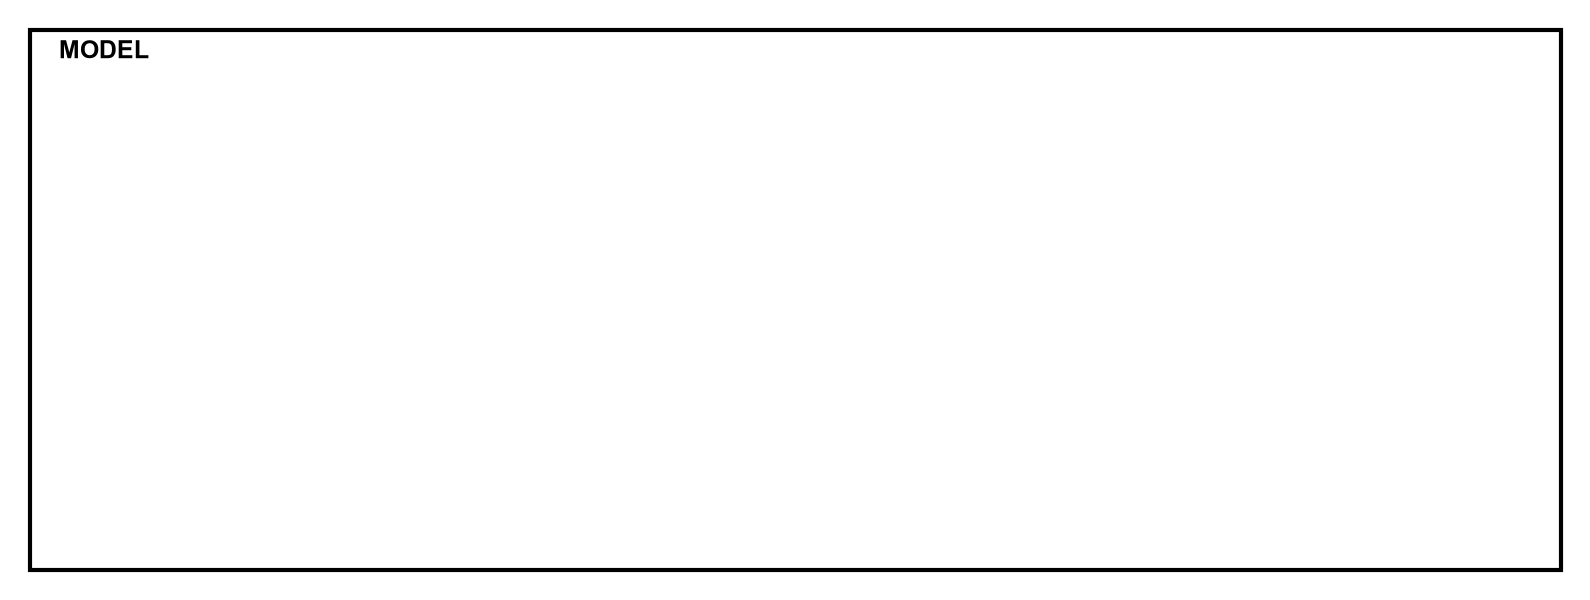

In [14]:
fig, ax = panel_fig("fig2_ZZ", nrows=1) # the subplot you want to frame
bbox = ax.get_position()  # returns a Bbox object

x0 = bbox.x0  # left edge
y0 = bbox.y0  # bottom edge
width = bbox.width
height = bbox.height

# Then use these in FancyBboxPatch
rect = patches.FancyBboxPatch(
    (x0, y0), width, height,
    boxstyle="square,pad=0.01",  # pad adds a small margin around the axes
    linewidth=1,
    edgecolor='black',
    facecolor='none',
    transform=fig.transFigure,
    clip_on=False
)
fig.add_artist(rect)
ax.set_visible(False)
fig.text(x0 - 0.01 + 0.015, y0 + height + 0.01 - 0.015, "MODEL", ha="left", va="top", fontsize=6, fontweight="bold", color="black")
plt.show()
save_panel(fig, PANELS_DIR / "fig2_ZZ.pdf")

## Data loading

Three separate cohorts with different exclusion sets and stage filters.

In [4]:
# --- Data loading for three cohorts ---

# Cohort 1: fig4 (base behaviour)
EXCLUDED_FIG4 = {713578, 754575, 715866}
_, _, macro4 = data_access.load_session_catalogue_and_sites(
    S3_ROOT, STORAGE_OPTIONS, EXCLUDED_FIG4
)
macro4 = data_access.prepare_macro_df(
    macro4,
    stage_filter=("data_collection", "control"),
    stages_csv=STAGES_CSV,
)
all_df4 = data_access.build_all_df(macro4)
all_df4 = all_df4[all_df4["site_label"] == "RewardSite"].copy()
print(f"Cohort fig4: {all_df4['mouse'].nunique()} mice, {all_df4['session_id'].nunique()} sessions")

# Cohort 2: fig6 (travel-cost manipulations)
EXCLUDED_FIG6 = {
    "707349", "713545", "713578", "715865", "715866", "715867",
    "715869", "715870", "716455", "716456", "716457", "716458",
}
STAGES_FIG6 = (
    "data_collection", "control",
    "friction", "friction_low", "friction_med", "friction_high",
    "distance_short", "distance_long", "distance_extra_short", "distance_extra_long",
)
_, _, macro6 = data_access.load_session_catalogue_and_sites(
    S3_ROOT, STORAGE_OPTIONS, EXCLUDED_FIG6
)
macro6 = data_access.prepare_macro_df(
    macro6, stage_filter=STAGES_FIG6, stages_csv=STAGES_CSV,
)
all_df6 = data_access.build_all_df(macro6)
all_df6 = all_df6[all_df6["site_label"] == "RewardSite"].copy()
print(f"Cohort fig6: {all_df6['mouse'].nunique()} mice, {all_df6['session_id'].nunique()} sessions")

# Cohort 3: fig7 (global reward manipulations)
EXCLUDED_FIG7 = {
    "754570", "754579", "754567", "754580", "754559", "754560", "754577",
    "754566", "754571", "754574", "754575", "754582", "745302", "745305", "745301",
}
STAGES_FIG7 = ("data_collection", "base", "control", "experiment1")
_, _, macro7 = data_access.load_session_catalogue_and_sites(
    S3_ROOT, STORAGE_OPTIONS, EXCLUDED_FIG7
)
macro7 = data_access.prepare_macro_df(
    macro7, stage_filter=STAGES_FIG7, stages_csv=STAGES_CSV, relabel_patches=False,
)
all_df7 = data_access.build_all_df(macro7)
all_df7 = all_df7[all_df7["site_label"] == "RewardSite"].copy()

# Remap odor names → tier labels for fig7
label_map = {
    "Alpha pinene": "60", "Alpha-pinene": "60",
    "Methyl Butyrate": "90", "Ethyl Butyrate": "90",
    "Amyl Acetate": "0", "Fenchone": "0",
}
all_df7["patch_label"] = all_df7["patch_label"].map(label_map).fillna(all_df7["patch_label"])
all_df7.loc[all_df7["stage_name"] == "base", "stage_name"] = "control"

# Build environment label per session (high/low based on max reward_probability in experiment1)
_manip1 = all_df7[
    (all_df7["stage_name"] == "experiment1") & (all_df7["patch_label"] != "0")
]
_sess_env = (
    _manip1.groupby("session_id")["reward_probability"].max().reset_index()
)
_sess_env.columns = ["session_id", "max_rp"]
_sess_env["environment"] = _sess_env["max_rp"].apply(
    lambda x: "high" if (pd.notna(x) and x > 0.6) else "low"
)
all_df7 = all_df7.merge(
    _sess_env[["session_id", "environment"]], on="session_id", how="left"
)
all_df7["environment"] = all_df7["environment"].fillna("mix")
print(f"Cohort fig7: {all_df7['mouse'].nunique()} mice, {all_df7['session_id'].nunique()} sessions")


Cohort fig4: 24 mice, 712 sessions
Cohort fig6: 15 mice, 919 sessions
Cohort fig7: 12 mice, 365 sessions


## Panel A — MVT schematic

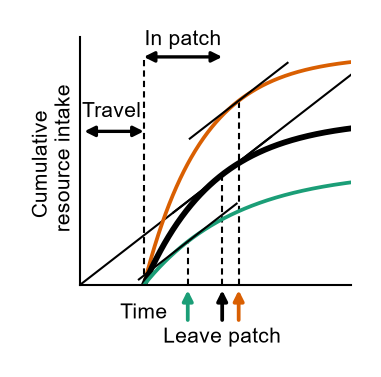

In [5]:
# --- Panel A: MVT schematic (after Charnov 1976) ---
def plot_mvt_schematic(travel_time=2.0):
    # (A, k, color); order = high, mid (global average), low
    patches = [
        dict(A=9.0, k=0.55, color=color1),
        dict(A=6.5, k=0.45, color="black", lw=1.4),
        dict(A=4.5, k=0.35, color=color2),
    ]
    T = travel_time

    def gain(tau, A, k):
        return A * (1 - np.exp(-k * tau))

    # Black curve sets the average rate: line from origin tangent to it
    p = patches[1]
    tau_opt = brentq(
        lambda t: gain(t, p["A"], p["k"]) / (t + T) - p["A"] * p["k"] * np.exp(-p["k"] * t),
        0.1, 30,
    )
    slope = gain(tau_opt, p["A"], p["k"]) / (tau_opt + T)

    # Each patch is left where its marginal rate equals the average rate
    for pp in patches:
        pp["tau_leave"] = np.log(pp["A"] * pp["k"] / slope) / pp["k"]

    x_max = T + patches[0]["tau_leave"] + 3.5
    y_max = patches[0]["A"] * 1.08

    fig, ax1 = panel_fig("fig2_A")
    tau = np.linspace(0, x_max - T, 400)
    # Global average-rate line from the origin
    ax1.plot([0, x_max], [0, slope * x_max], color="black", linewidth=0.5, zorder=1)

    for pp in patches:
        ax1.plot(T + tau, gain(tau, pp["A"], pp["k"]), color=pp["color"],
                linewidth=pp.get("lw", 0.9), zorder=2)
        # tangent (parallel to the average-rate line) at the leaving point
        tl = pp["tau_leave"]
        x0, y0 = T + tl, gain(tl, pp["A"], pp["k"])
        dx = 0.18 * x_max
        ax1.plot([x0 - dx, x0 + dx], [y0 - slope * dx, y0 + slope * dx],
                color="black", linewidth=0.5, zorder=3)
        ax1.plot([x0, x0], [-0.0, y0], color="black", linestyle=(0, (3, 2)),
                linewidth=0.5, zorder=1)

    # patch-entry dashed line
    ax1.plot([T, T], [0, y_max * 0.92], color="black", linestyle=(0, (3, 2)),
            linewidth=0.5, zorder=1)

    # Travel / In patch brackets
    y_arrow = y_max * 0.62
    arrow = dict(arrowstyle="<|-|>", color="black", linewidth=0.8,
                 mutation_scale=5, shrinkA=0, shrinkB=0)
    ax1.annotate("", xy=(0.15, y_arrow), xytext=(T, y_arrow), arrowprops=arrow)
    ax1.text(T / 2, y_arrow + 0.04 * y_max, "Travel", ha="center", va="bottom")
    x_black = T + patches[1]["tau_leave"]
    y_in = y_max * 0.92
    ax1.annotate("", xy=(T, y_in), xytext=(x_black, y_in), arrowprops=arrow)
    ax1.text((T + x_black) / 2, y_in + 0.03 * y_max, "In patch", ha="center", va="bottom")
    # Leave arrows below the axis
    y_a0, y_a1 = -0.02 * y_max, -0.14 * y_max
    for pp in patches:
        xl = T + pp["tau_leave"]
        ax1.annotate("", xy=(xl, y_a0), xytext=(xl, y_a1),
                    arrowprops=dict(arrowstyle="-|>", color=pp["color"],
                                    linewidth=0.9, mutation_scale=5,
                                    shrinkA=0, shrinkB=0),
                    annotation_clip=False)
    ax1.text(x_black, y_a1 - 0.03 * y_max, "Leave patch", ha="center", va="top",
            clip_on=False)
    ax1.text(T, y_a1 * 0.8, "Time", ha="center", va="center", clip_on=False)

    # ax.set_xlim(0, x_max)
    # ax.set_ylim(-0.42 * y_max, y_max * 1.18)
    # start both axes exactly at 0 so the curves touch the spines (no default margin)
    ax1.set_xlim(0, x_max)
    ax1.set_ylim(0, y_max)
    ax1.set_xticks([])
    ax1.set_yticks([])
    ax1.set_ylabel("Cumulative \n resource intake")
    plt.tight_layout()
    return fig, ax1

apply_style()
fig, ax1 = plot_mvt_schematic(travel_time=2.0)
plt.show()
save_panel(fig, PANELS_DIR / "fig2_A.pdf")

## Panel C — 6-metric comparison (1 × 2)

In [6]:
# --- Panel C preparation: aggregate data for 6-metric comparison ---
groups = ["session_id", "mouse", "patch_index", "patch_label", "stage_name"]

pre_df4 = all_df4[
    (all_df4["last_visit"] == 1)
    & (all_df4["patch_index"] <= 50)
    & (all_df4["stage_name"].isin(["control", "data_collection"]))
]

mouse_df4 = (
    pre_df4.groupby(groups)
    .agg(
        site_number=("site_index_in_patch_by_type", "max"),
        reward_probability=("reward_probability", "min"),
        stops=("site_index_in_patch_by_type", "max"),
        total_rewards=("cumulative_rewards", "max"),
        consecutive_rewards=("consecutive_rewards", "max"),
        total_failures=("cumulative_failures", "max"),
        consecutive_failures=("consecutive_failures", "max"),
        time_patch=("exit_epoch", "max"),
    )
    .reset_index()
)

general_df4 = (
    mouse_df4.groupby(["mouse", "patch_label", "stage_name"])
    .agg(
        reward_probability=("reward_probability", "mean"),
        stops=("stops", "mean"),
        total_rewards=("total_rewards", "mean"),
        consecutive_failures=("consecutive_failures", "mean"),
        total_failures=("total_failures", "mean"),
        time_patch=("time_patch", "mean"),
    )
    .reset_index()
)
print(f"general_df4: {len(general_df4)} rows, {general_df4['mouse'].nunique()} mice")


general_df4: 108 rows, 24 mice


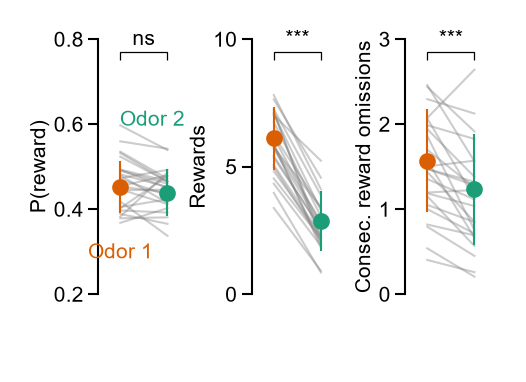

In [7]:
# --- Panel C: 6-metric comparison (2 × 3 multi-panel) ---
apply_style()
from adaptive_behavior.style import make_fig, PANEL_MM
fig, axes = make_fig(*PANEL_MM["fig2_B"], nrows=1, ncols=3)  # real 3 axes (panel_fig(ncols=3) returns one 2/3-width axes)
axes = axes.flatten()

metric_cfg = [
    ("reward_probability", "P(reward)", (0.2, 0.8), np.arange(0.2, 0.81, 0.2)),
    # ("stops",              "Stops",     (0, 20),     None),
    ("total_rewards",      "Rewards",   (0, 10),     None),
    ("consecutive_failures","Consec. reward omissions", (0, 3), None),
    # ("total_failures",     "Total omissions", (0, 12.5), np.arange(0, 13, 5)),
    # ("time_patch",         "Time in patch",   (0, 150),  np.arange(0, 151, 50)),
]

for ax, (var, title, ylim, yticks) in zip(axes, metric_cfg):
    plotting.plot_condition_comparison(
        general_df4,
        variable=var,
        condition="mouse",
        odor_labels=["90", "60"],
        color_dict=color_dict_label,
        ax=ax,
    )
    ax.set_ylabel(title)
    ax.tick_params(axis="x", colors="white")  # keep x ticks/labels (for spacing) but invisible
    ax.set_xlabel("delta", color="white")
    ax.set_ylim(ylim)
    if yticks is not None:
        ax.set_yticks(yticks)

# odor legend in text, in the matching colours
axes[0].text(0.60, 0.2, "Odor 1", color=color1, transform=axes[0].transAxes, ha="right", va="top")
axes[0].text(0.95, 0.72, "Odor 2", color=color2, transform=axes[0].transAxes, ha="right", va="top")

plt.tight_layout(w_pad=0.0)
plt.show()
save_panel(fig, PANELS_DIR / "fig2_B.pdf")

## Panel E — P(leave) by consecutive omissions (mice)

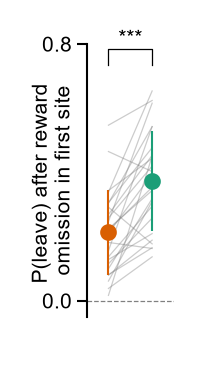

In [18]:
# --- Panel E: P(leave) by consecutive omissions (mice) ---
plot = (
    all_df4.loc[
        (all_df4["cumulative_rewards"] == 0)
        & (all_df4["consecutive_failures"] != 0)
        & (all_df4["consecutive_failures"] <= 2)
        & (all_df4["patch_label"].isin(["60", "90"]))
    ]
    .groupby(["mouse", "patch_label", "consecutive_failures"])
    .agg({"has_choice": "mean"})
    .reset_index()
)
plot["leave_probability"] = 1 - plot["has_choice"]

wide = plot.pivot_table(
    index=["mouse", "consecutive_failures"],
    columns="patch_label",
    values="leave_probability",
).reset_index()
wide["60"] = wide["60"].astype(float)
wide["90"] = wide["90"].astype(float)

pvals = {}
for cf, sub in wide.groupby("consecutive_failures"):
    sub = sub.dropna(subset=["60", "90"])
    if len(sub) > 1:
        _, p = ttest_rel(sub["60"], sub["90"])
        pvals[cf] = p
    else:
        pvals[cf] = float("nan")

cf_list = [1]
plot_sub = plot[plot["consecutive_failures"].isin(cf_list)]
wide_sub = wide[wide["consecutive_failures"].isin(cf_list)]

fig, ax = panel_fig("fig2_C")
hue_order = ["90", "60"]
palette_f = {"90": color1, "60": color2}
x_ticks = sorted(plot_sub["consecutive_failures"].unique())
tick_to_int = {v: i for i, v in enumerate(x_ticks)}
offsets = np.linspace(-0.25, 0.25, 2)
hue_offset = {hue: offsets[i] for i, hue in enumerate(hue_order)}
x_lim = (-0.5, len(x_ticks) - 1 + 0.5)

for _, mouse_row in wide_sub.iterrows():
    for cf in x_ticks:
        row = wide_sub[
            (wide_sub["mouse"] == mouse_row["mouse"])
            & (wide_sub["consecutive_failures"] == cf)
        ]
        if row.empty:
            continue
        xs = [tick_to_int[cf] + hue_offset[h] for h in hue_order if not pd.isna(row[h].values[0])]
        ys = [row[h].values[0] for h in hue_order if not pd.isna(row[h].values[0])]
        if len(xs) == 2:
            ax.plot(xs, ys, color="gray", alpha=0.4, linewidth=0.3, zorder=5)

for hue in hue_order:
    for cf in x_ticks:
        subset = plot_sub[
            (plot_sub["consecutive_failures"] == cf) & (plot_sub["patch_label"] == hue)
        ]["leave_probability"]
        if subset.empty:
            continue
        x_pos = tick_to_int[cf] + hue_offset[hue]
        ax.errorbar(
            x_pos, subset.mean(), yerr=subset.std(),
            fmt="o", color=palette_f[hue], markersize=3,
            capsize=0, capthick=0, elinewidth=0.5, zorder=10,
            label=hue if cf == x_ticks[0] else "",
        )

bracket_h, y_pad = 0.05, 0.08
for cf, p in {k: v for k, v in pvals.items() if k in cf_list}.items():
    if pd.isna(p):
        continue
    sig = "***" if p < 0.001 else ("**" if p < 0.01 else ("*" if p < 0.05 else "ns"))
    xi = tick_to_int[cf]
    x1, x2 = xi + hue_offset["90"], xi + hue_offset["60"]
    y_top = plot_sub.loc[plot_sub["consecutive_failures"] == cf, "leave_probability"].max()
    y_bar = y_top + y_pad
    ax.plot([x1, x1, x2, x2], [y_bar, y_bar + bracket_h, y_bar + bracket_h, y_bar], color="black")
    ax.text((x1 + x2) / 2, y_bar + bracket_h, sig, ha="center", va="bottom")

ax.set_xticks([hue_offset[h] for h in hue_order], hue_order)  # same ticks as B, drawn white
ax.set_xlim(x_lim)
ax.set_ylim(-0.05, 0.8)
ax.set_yticks([0, 0.8])
ax.set_xlabel("")
ax.set_ylabel("P(leave) after reward \nomission in first site", labelpad=-8)
ax.hlines(0, x_lim[0], x_lim[1], colors="grey", linestyles="dashed")
sns.despine(ax=ax, bottom=True)  # also hide the x axis line
ax.tick_params(axis="x", colors="white", bottom=True) 
plt.tight_layout()
plt.show()
save_panel(fig, PANELS_DIR / "fig2_C.pdf")

## Panels G & I — Travel cost manipulations (fig6 cohort)

Aggregate and helper function shared by both panels.

In [19]:
# --- Panels G & I preparation: travel-cost aggregation (fig6 cohort) ---
groups6 = ["session_id", "mouse", "patch_index", "patch_label", "stage_name"]

pre_df6 = all_df6[
    (all_df6["patch_label"].isin(["90", "60"]))
    & (all_df6["last_visit"] == 1)
    & (all_df6["site_index_in_patch_by_type"] > 0)
    & (all_df6["patch_index"] <= 50)
]

mouse_df6 = (
    pre_df6.groupby(groups6)
    .agg(
        reward_probability=("reward_probability", "min"),
        stops=("site_index_in_patch_by_type", "max"),
        total_rewards=("cumulative_rewards", "max"),
        consecutive_failures=("consecutive_failures", "max"),
        total_failures=("cumulative_failures", "max"),
    )
    .reset_index()
)

general_df6 = (
    mouse_df6.groupby(["mouse", "stage_name"])
    .agg(
        reward_probability=("reward_probability", "mean"),
        stops=("stops", "mean"),
        total_rewards=("total_rewards", "mean"),
        consecutive_failures=("consecutive_failures", "mean"),
        total_failures=("total_failures", "mean"),
    )
    .reset_index()
    .rename(columns={"stage_name": "experiment"})
)

In [10]:
def plot_travel_cost(
    general_df,
    variable='reward_probability',
    experiment_variable='friction',
    mean='friction_low',
    panel_key=None,
    plot_style='dots',  # 'dots' or 'boxplot'
    per_mouse=True,
):
    labels_dict = {
        'data_collection': 'Data collection',
        'control': 'None',
        'friction_low': 'Low', 'friction_med': 'Med.', 'friction_high': 'High',
        'distance_short': 'Dis. short', 'distance_long': 'Dis. long',
        'distance_extra_short': 'Ext. short', 'distance_extra_long': 'Ext. long',
        'odor_60': 'Low', 'odor_90': 'High',
    }

    variable = variable.removesuffix('_norm')

    summary_df = general_df.copy()
    summary_df['mouse'] = summary_df['mouse'].astype(str)
    norm_var = variable + '_norm'
    if per_mouse:
        ref_vals = summary_df.loc[summary_df['experiment'] == mean, ['mouse', variable]].set_index('mouse')[variable]
        summary_df[norm_var] = summary_df[variable] - summary_df['mouse'].map(ref_vals)
    else:
        control_mean = summary_df.loc[summary_df['experiment'] == mean, variable].mean()
        summary_df[norm_var] = summary_df[variable] - control_mean

    if experiment_variable == 'friction':
        experiments = (
            ['friction_low', 'friction_med', 'friction_high'] if mean == 'friction_low'
            else ['control', 'friction_low', 'friction_med', 'friction_high']
        )
        xlabel = 'Added inter-patch friction (a.u.)'
    else:
        experiments = [
            'distance_extra_short', 'distance_short', 'control',
            'distance_long', 'distance_extra_long',
        ]
        xlabel = 'Inter-patch travel distance (cm)'

    labels_plot = [labels_dict[e] for e in experiments]
    if experiment_variable != "friction":
        labels_plot = ["50", "150", "300", "450", "600"]

    # Per-condition color palette (shared by both plot styles)
    if experiment_variable == 'friction':
        _blues = plt.cm.Blues(np.linspace(0.4, 0.9, 3))
        condition_colors = {
            'control': '#888888',
            'friction_low': _blues[0],
            'friction_med': _blues[1],
            'friction_high': _blues[2],
        }
    else:
        _reds = plt.cm.Reds(np.linspace(0.4, 0.9, 4))
        condition_colors = {
            'control': '#888888',
            'distance_extra_short': _reds[0],
            'distance_short': _reds[1],
            'distance_long': _reds[2],
            'distance_extra_long': _reds[3],
        }

    if panel_key:
        fig, ax = panel_fig(panel_key)
    else:
        fig, ax = plt.subplots(1, 1, figsize=(4.75, 4.25))

    if plot_style == 'boxplot':
        sns.boxplot(
            x='experiment', y=norm_var, data=summary_df,
            palette=condition_colors, showfliers=False, ax=ax, order=experiments,
            linewidth=0,
            medianprops=dict(color='white', linewidth=1),
            whiskerprops=dict(color='black', linewidth=1),
            capprops=dict(color='k', linewidth=1),
            flierprops=dict(marker=''),
        )
        sns.swarmplot(
            x='experiment', y=norm_var, hue='mouse', zorder=3,
            size=3, palette = np.repeat('black', summary_df['mouse'].nunique()),
            data=summary_df, dodge=False, ax=ax, order=experiments, legend=False
        )
        ax.hlines(
            summary_df.loc[summary_df['experiment'] == mean, norm_var].mean(),
            -0.5, len(experiments) - 0.5,
            linestyles='dashed', alpha=0.5, color='grey',
        )
        ax.set_xticks(np.arange(len(experiments)), labels_plot)
        plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    else:
        x_map = {exp: i for i, exp in enumerate(experiments)}
        for mouse, mdf in summary_df[summary_df['experiment'].isin(experiments)].groupby('mouse'):
            pts = mdf.set_index('experiment')[norm_var].reindex(experiments).dropna()
            if len(pts) >= 2:
                ax.plot(
                    [x_map[e] for e in pts.index], pts.values,
                    color='gray', alpha=0.4, linewidth=0.5, marker='',
                )
        for exp in experiments:
            subset = summary_df.loc[summary_df['experiment'] == exp, norm_var].dropna()
            if subset.empty:
                continue
            c = condition_colors.get(exp, '#444444')
            ax.errorbar(
                x_map[exp], subset.mean(), yerr=subset.std(),
                fmt='o', color=c,
                capsize=0, capthick=0, elinewidth=0.5,
                markersize=2, zorder=10,
            )
        ax.axhline(0, color='black', linestyle='--', alpha=1, linewidth=1)
        ax.set_xticks(list(x_map.values()), labels_plot)
        plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
        

    # Significance vs reference condition (paired t-test per mouse)
    ref_vals = summary_df.loc[summary_df['experiment'] == mean].set_index('mouse')[norm_var]
    y_top = ax.get_ylim()[1]
    for i, exp in enumerate(experiments):
        if exp == mean:
            continue
        exp_vals = summary_df.loc[summary_df['experiment'] == exp].set_index('mouse')[norm_var]
        paired = pd.concat([ref_vals, exp_vals], axis=1, join='inner').dropna()
        paired.columns = ['ref', 'exp']
        if len(paired) < 3:
            continue
        try:
            _, p = ttest_rel(paired['ref'], paired['exp'])
        except Exception:
            continue
        sig = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'ns'))
        x_pos = i if plot_style == 'dots' else i
        ax.text(x_pos, y_top, sig, ha='center', va='top', fontsize=5)

    if norm_var == 'reward_probability_norm':
        ax.set_ylabel('ΔP(reward) at leaving', labelpad=1)
    elif norm_var == 'stops_norm':
        ax.set_ylabel('ΔStops per patch')
    else:
        ax.set_ylabel(norm_var.replace('_', ' '))

    ax.set_xlabel(xlabel)
    ax.tick_params(axis='y', pad=1)  # y tick labels closer to the ticks
    sns.despine(ax=ax)
    plt.tight_layout()
    return fig, ax

## Panel G — Distance manipulation

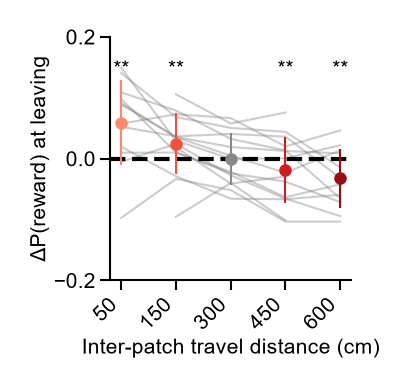

In [20]:
# --- Panel G: Distance manipulation ---
fig, ax = plot_travel_cost(
    general_df6,
    variable="reward_probability",
    experiment_variable="distance",
    mean="control",
    panel_key="fig2_D",
    plot_style="dots",
    per_mouse=False,
)
ax.set_ylim(-0.2, 0.2)
ax.set_yticks([-0.2, 0, 0.2])
plt.show()
save_panel(fig, PANELS_DIR / "fig2_D.pdf")

## Panel I — Friction manipulation

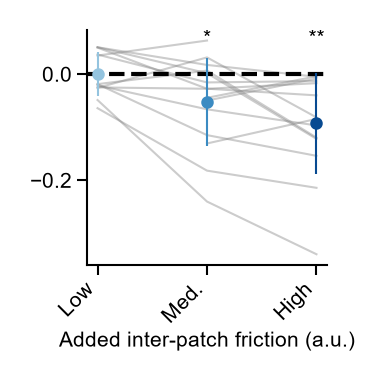

In [12]:
# --- Panel I: Friction manipulation ---
fig, ax = plot_travel_cost(
    general_df6,
    variable="reward_probability",
    experiment_variable="friction",
    mean="friction_low",
    panel_key="fig2_E",
    plot_style="dots",
    per_mouse=False,
)

ax.set_ylabel("")
plt.show()
save_panel(fig, PANELS_DIR / "fig2_E.pdf")

## Panels K, L, N, O — Global reward manipulations (fig7 cohort)

Aggregate and helper function shared by panels H and I.

In [13]:
# --- Panels K, L, N, O preparation: global reward aggregation (fig7 cohort) ---
groups7 = ["session_id", "mouse", "patch_index", "patch_label", "stage_name", "environment"]

pre_df7 = all_df7[
    (all_df7["patch_label"] != "0")
    & (all_df7["last_visit"] == 1)
    & (all_df7["patch_index"] <= 50)
]
pre_df7 = pre_df7.loc[
    ((pre_df7["site_index_in_patch_by_type"] > 1) & (pre_df7["patch_label"] == "90"))
    | (pre_df7["stage_name"] == "experiment1")
    | (pre_df7["patch_label"] == "60")
]
mouse_df7 = (
    pre_df7.groupby(groups7)
    .agg(
        reward_probability=("reward_probability", "min"),
        stops=("site_index_in_patch_by_type", "max"),
        total_rewards=("cumulative_rewards", "max"),
        consecutive_failures=("consecutive_failures", "max"),
        total_failures=("cumulative_failures", "max"),
    )
    .reset_index()
    .rename(columns={"stage_name": "experiment"})
)

general_df7 = (
    mouse_df7.groupby(["mouse", "patch_label", "experiment", "environment"])
    .agg(
        reward_probability=("reward_probability", "mean"),
        stops=("stops", "mean"),
        total_rewards=("total_rewards", "mean"),
        consecutive_failures=("consecutive_failures", "mean"),
        total_failures=("total_failures", "mean"),
    )
    .reset_index()
)
print(f"general_df7: {len(general_df7)} rows, {general_df7['mouse'].nunique()} mice")


general_df7: 44 rows, 12 mice


In [14]:
# Helper: plot change in reward probability between control and experiment1
def plot_reward_diff(general_df, environment="high", variable="reward_probability", ax=None):
    summary = general_df.copy()
    mouse_list = summary.loc[summary["environment"] == environment, "mouse"].unique()
    patch_order = ["90", "60"]
    patch_colors = {"60": color2, "90": color1}
    x_map = {pl: i for i, pl in enumerate(patch_order)}

    if ax is None:
        fig, ax = plt.subplots(1, 1, figsize=(4.25, 4.25))
    else:
        fig = ax.get_figure()

    all_diffs = []
    for pl in patch_order:
        base = (
            summary.loc[
                (summary["experiment"] == "control")
                & (summary["environment"] == "mix")
                & (summary["mouse"].isin(mouse_list))
                & (summary["patch_label"] == pl)
            ][["mouse", variable]]
            .rename(columns={variable: "base"})
        )
        manip = (
            summary.loc[
                (summary["experiment"] == "experiment1")
                & (summary["environment"] == environment)
                & (summary["mouse"].isin(mouse_list))
                & (summary["patch_label"] == pl)
            ][["mouse", variable]]
            .rename(columns={variable: "manip"})
        )
        diff_df = base.merge(manip, on="mouse")
        diff_df["difference"] = diff_df["manip"] - diff_df["base"]
        diff_df["patch_label"] = pl
        all_diffs.append(diff_df)

    combined = pd.concat(all_diffs, ignore_index=True)

    # Gray connecting lines per mouse
    pivot = combined.pivot(index="mouse", columns="patch_label", values="difference")
    for _, row in pivot.iterrows():
        vals = row.reindex(patch_order).dropna()
        if len(vals) == 2:
            ax.plot([x_map[pl] for pl in vals.index], vals.values,
                    color="gray", alpha=0.4, linewidth=0.5)

    # Mean +/- SD dots
    for pl in patch_order:
        vals = combined.loc[combined["patch_label"] == pl, "difference"].dropna()
        ax.errorbar(
            x_map[pl], vals.mean(), yerr=vals.std(),
            fmt="o", color=patch_colors[pl],
            capsize=0, capthick=0, elinewidth=0.8, markersize=3, zorder=10,
        )

    ax.set_xlim(-0.5, 1.5)
    ax.axhline(0, color="gray", linestyle="--", linewidth=1, zorder=5)
    # keep the x ticks/labels so the layout matches neighbouring panels, but draw them white
    ax.set_xticks(list(x_map.values()), ["Patch 90", "Patch 60"])
    ax.tick_params(axis="x", colors="white")
    # Significance: paired t-test between patch types
    p60 = combined.loc[combined["patch_label"] == "60"].set_index("mouse")["difference"]
    p90 = combined.loc[combined["patch_label"] == "90"].set_index("mouse")["difference"]
    paired = pd.concat([p60, p90], axis=1, join="inner").dropna()
    paired.columns = ["p60", "p90"]
    if len(paired) >= 3:
        _, p = ttest_rel(paired["p60"], paired["p90"])
        sig = "***" if p < 0.001 else ("**" if p < 0.01 else ("*" if p < 0.05 else "ns"))
        y_lo, y_hi = ax.get_ylim()
        pad = (y_hi - y_lo) * 0.06
        y_bracket = combined["difference"].max() + pad
        ax.set_ylim(top=y_bracket + pad)
        ax.plot([0, 1], [y_bracket, y_bracket], color="black", linewidth=0.8)
        ax.text(0.5, y_bracket + pad * 0.3, sig, ha="center", va="bottom", fontsize=5)

    ylabel_map = {
        "reward_probability": "\u0394P(reward) at leaving",
        "total_rewards": "\u0394Rewards collected",
        "stops": "\u0394Stops",
    }
    ax.set_ylabel(ylabel_map.get(variable, f"\u0394{variable}"))
    sns.despine(ax=ax, bottom=True)  # also hide the x axis line
    return fig, ax


## Panels K & N — Transition schematics

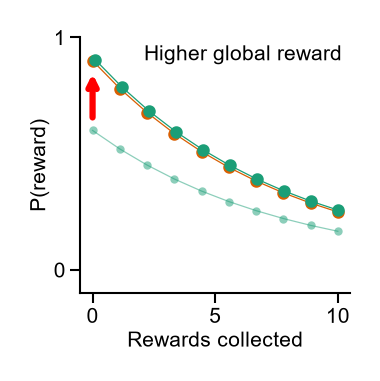

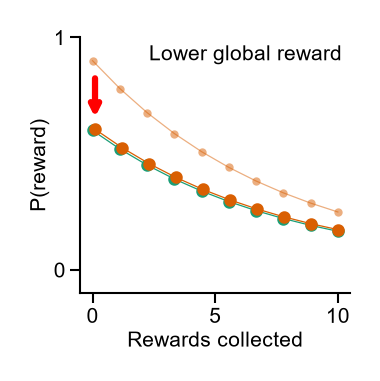

In [10]:
# --- Panels K and N: Global-reward transition schematics ---
apply_style()

max_x = 10
b = math.e
c = 0.1284
marker = "o"
x = np.linspace(0, max_x, max_x)
x_shift, y_shift = 0.1, 0.005
x_s = np.linspace(x_shift, max_x, max_x)


def style_transition_ax(ax, title):
    ax.set_ylabel("P(reward)")
    ax.set_xlabel("Rewards collected")
    ax.set_ylim(-0.1, 1)
    ax.set_xlim(-0.5, max_x + 0.5)
    ax.yaxis.set_major_locator(FixedLocator([0, 0.5, 1]))
    ax.xaxis.set_major_locator(FixedLocator(np.arange(0, max_x + 1, 5)))
    ax.text(0.97, 0.97, title, transform=ax.transAxes, ha="right", va="top", fontsize=5)  # inside the plot
    sns.despine(ax=ax)


# Panel K: Low -> High transition
fig, ax = panel_fig("fig2_F", ncols=3)
a = 0.9
ax.plot(x, a * b ** (-c * x), color=color1, marker=marker, markersize=2)
a = 0.6
ax.plot(x, a * b ** (-c * x), color=color2, marker=marker, alpha=0.5, markersize=2, markeredgewidth=0)
a = 0.9
ax.plot(x_s, a * b ** (-c * (x_s - x_shift)) + y_shift, color=color2, marker=marker, alpha=1, markersize=2)
ax.annotate("", xy=(0, 0.88), xytext=(0, 0.62),
            arrowprops=dict(arrowstyle="->", color="red", lw=1.5))
style_transition_ax(ax, "Higher global reward")
plt.yticks([0, 1])
plt.tight_layout()
plt.show()
save_panel(fig, PANELS_DIR / "fig2_F.pdf")

# Panel N: High -> Low transition
fig, ax = panel_fig("fig2_F", ncols=3)
a = 0.6
ax.plot(x_s, a * b ** (-c * (x_s - x_shift)) + y_shift, color=color1, marker=marker, markersize=2, zorder=10)
a = 0.6
ax.plot(x, a * b ** (-c * x), color=color2, marker=marker, markersize=2)
a = 0.9
ax.plot(x, a * b ** (-c * x), color=color1, marker=marker, alpha=0.5, markersize=2, markeredgewidth=0)
ax.annotate("", xy=(0.1, 0.86), xytext=(0.1, 0.62),
            arrowprops=dict(arrowstyle="<-", color="red", lw=1.5))
style_transition_ax(ax, "Lower global reward")
plt.yticks([0, 1])
plt.tight_layout()
plt.show()
save_panel(fig, PANELS_DIR / "fig2_H.pdf")

## Panel L — Higher global reward

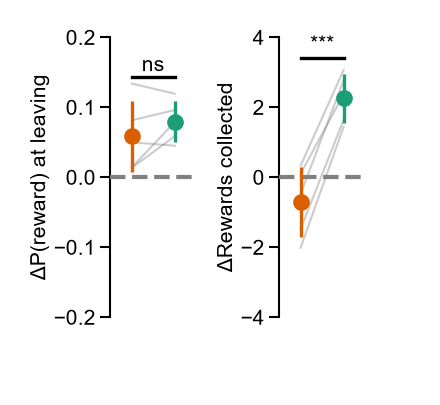

In [16]:
# --- Panel L: Higher global reward results ---
apply_style()
fig, axs = panel_fig("fig2_G", ncols=2)
plot_reward_diff(general_df7, environment="high", variable="reward_probability", ax=axs[0])
axs[0].set_ylim(-0.2, 0.2)
plot_reward_diff(general_df7, environment="high", variable="total_rewards", ax=axs[1])
axs[1].set_ylim(-4, 4)
# invisible (white) x label reserves the same height as the labelled neighbours (K, N)
for ax in axs:
    ax.set_xlabel("Rewards collected", color="white")
plt.tight_layout(w_pad=0.5, pad=0.5)
plt.show()
save_panel(fig, PANELS_DIR / "fig2_G.pdf")

## Panel O — Lower global reward

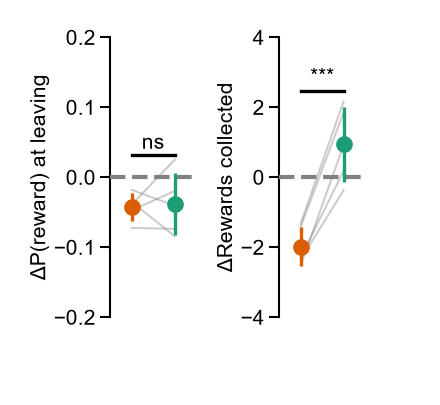

In [17]:
# --- Panel O: Lower global reward results ---
apply_style()
fig, axs = panel_fig("fig2_I", ncols=2)
plot_reward_diff(general_df7, environment="low", variable="reward_probability", ax=axs[0])
axs[0].set_ylim(-0.2, 0.2)
plot_reward_diff(general_df7, environment="low", variable="total_rewards", ax=axs[1])
axs[1].set_ylim(-4, 4)
# invisible (white) x label reserves the same height as the labelled neighbours (K, N)
for ax in axs:
    ax.set_xlabel("Rewards collected", color="white")
plt.tight_layout(w_pad=0.5, pad=0.5)
plt.show()
save_panel(fig, PANELS_DIR / "fig2_I.pdf")
